In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import skimage
from skimage.filters import threshold_otsu, median
from skimage.morphology import remove_small_objects, disk, remove_small_holes, closing

In [23]:
crop_dir = "/datafiles/crops/2951"
img_name = "24429_crop_g5.png"
# img_name = "24382_0_2_616_561_628_574.png"
# img_name = "24382_0_3_244_577_255_589.png"

In [24]:
import os
os.getcwd()

'/home/xgupke/Documents/projects/EmmaElinTrombocytes'

In [55]:
img = Image.open(f"{os.getcwd()}/{crop_dir}/{img_name}")
img = np.array(img)

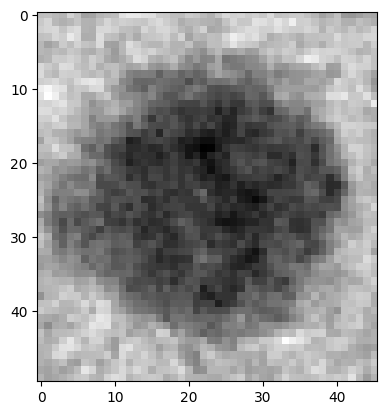

In [56]:
plt.imshow(img, cmap="gray")

In [57]:
def znorm(img):
    return (img - np.mean(img)) / np.std(img)

In [58]:
# normalize
# img = (img - img.min()) / (img.max() - img.min())
img = znorm(img)

Text(0.5, 1.0, 'Normalized Image')

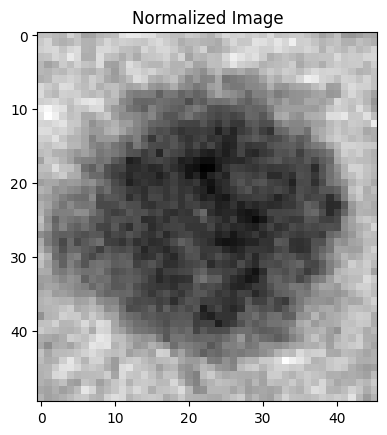

In [59]:
plt.imshow(img, cmap="gray")
plt.title('Normalized Image')

In [60]:
img_median = median(img, disk(3))

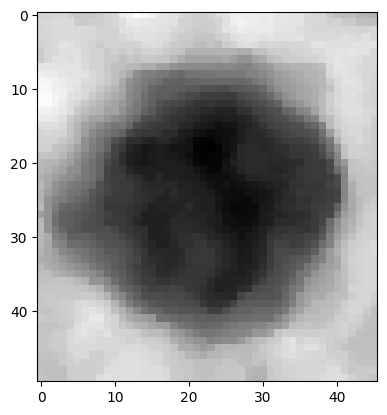

In [61]:
plt.imshow(img_median, cmap="gray")

In [62]:
from skimage.filters import gaussian

In [65]:
img_smooth = gaussian(img, sigma=1, preserve_range=True)

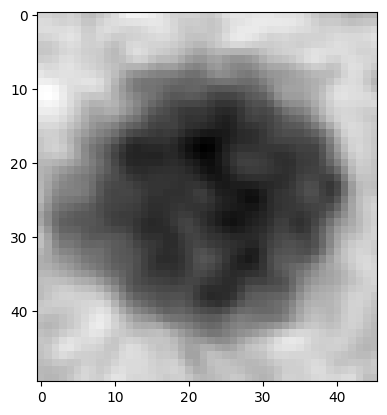

In [66]:
plt.imshow(img_smooth, cmap="gray")

In [34]:
disk(1)

array([[0, 1, 0],
       [1, 1, 1],
       [0, 1, 0]], dtype=uint8)

In [35]:
img_otsu = img < threshold_otsu(img)

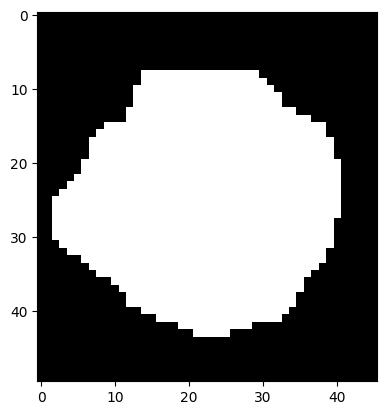

In [36]:
plt.imshow(img_otsu, cmap="gray")

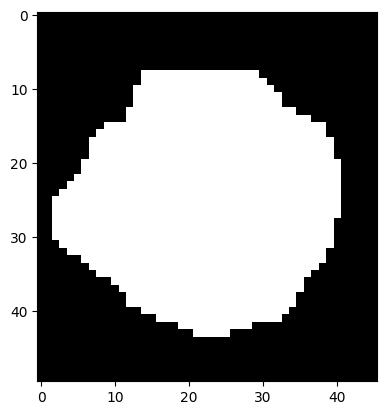

In [37]:
plt.imshow(remove_small_holes(img_otsu), cmap="gray")

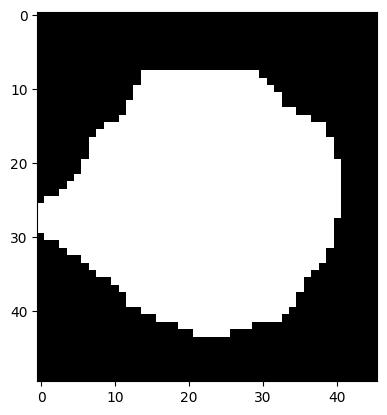

In [38]:
img_mask = remove_small_holes(img_otsu)
img_mask = remove_small_objects(img_mask, max_size=50)
img_mask = closing(img_mask, disk(3))
plt.imshow(img_mask, cmap="gray")

In [39]:
from skimage.measure import label, regionprops

pixel_size_nm = 3.224

lab = label(img_mask)
props = regionprops(lab)

# assuming one object
obj = props[0]

major = obj.axis_major_length
minor = obj.axis_minor_length
diameter_mean_axes = (major + minor) / 2

print("major axis:", major * pixel_size_nm)
print("minor axis:", minor * pixel_size_nm)
print("mean-axis diameter:", diameter_mean_axes * pixel_size_nm)

major axis: 122.97040896472869
minor axis: 113.5785309520044
mean-axis diameter: 118.27446995836654


In [69]:
'''
Let's collect the above operation into one function
Inputs: crop of the bounding box from the raw image array, 
        pixel size in nm, 
        diameter range, 
        max aspect ratio
Returns: diameter in nm given as major / minor axis length,
         boolean for whether granule is valid
         reason for invalidity if not valid
'''

def evaluate_granule(img_arr, pixel_size_nm, diameter_range=(50, 300), aspect_ratio_max=1.25):
    
    # normalize
    img = znorm(img_arr)
    # img = median(img, disk(3))
    img = gaussian(img, sigma=1, preserve_range=True)
    
    # thresholding
    img_otsu = img < threshold_otsu(img)
    
    # morphological operations
    img_mask = remove_small_holes(img_otsu)
    img_mask = remove_small_objects(img_mask, max_size=50)
    img_mask = closing(img_mask, disk(3))
    
    # labeling and region properties
    lab = label(img_mask)
    props = regionprops(lab)
    
    if len(props) == 0:
        return None  # No objects found
    
    obj = props[0]
    
    major = obj.axis_major_length
    minor = obj.axis_minor_length
    diameter_mean_axes = (major + minor) / 2
    
    # check the quality of the granule based on diameter and aspect ratio
    rejection_reason = "N.A."
    # Check diameter range and aspect ratio
    quality_check = True
    if not (diameter_range[0] <= diameter_mean_axes * pixel_size_nm <= diameter_range[1]):
        quality_check = False  # Diameter out of range
        rejection_reason = "Diameter out of range"
        return diameter_mean_axes * pixel_size_nm, quality_check, rejection_reason

    # check aspect ratio only if diameter is within range
    aspect_ratio = major / minor if minor != 0 else float('inf')
    if aspect_ratio > aspect_ratio_max:
        quality_check = False  # Aspect ratio too high
        rejection_reason = "Shape too thin"
    
    return img_mask, diameter_mean_axes * pixel_size_nm, quality_check, rejection_reason


In [70]:
evaluate_granule(img, pixel_size_nm=3.224, diameter_range=(50, 300), aspect_ratio_max=1.2)

(array([[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]], shape=(50, 46)),
 118.30601852167219,
 True,
 'N.A.')

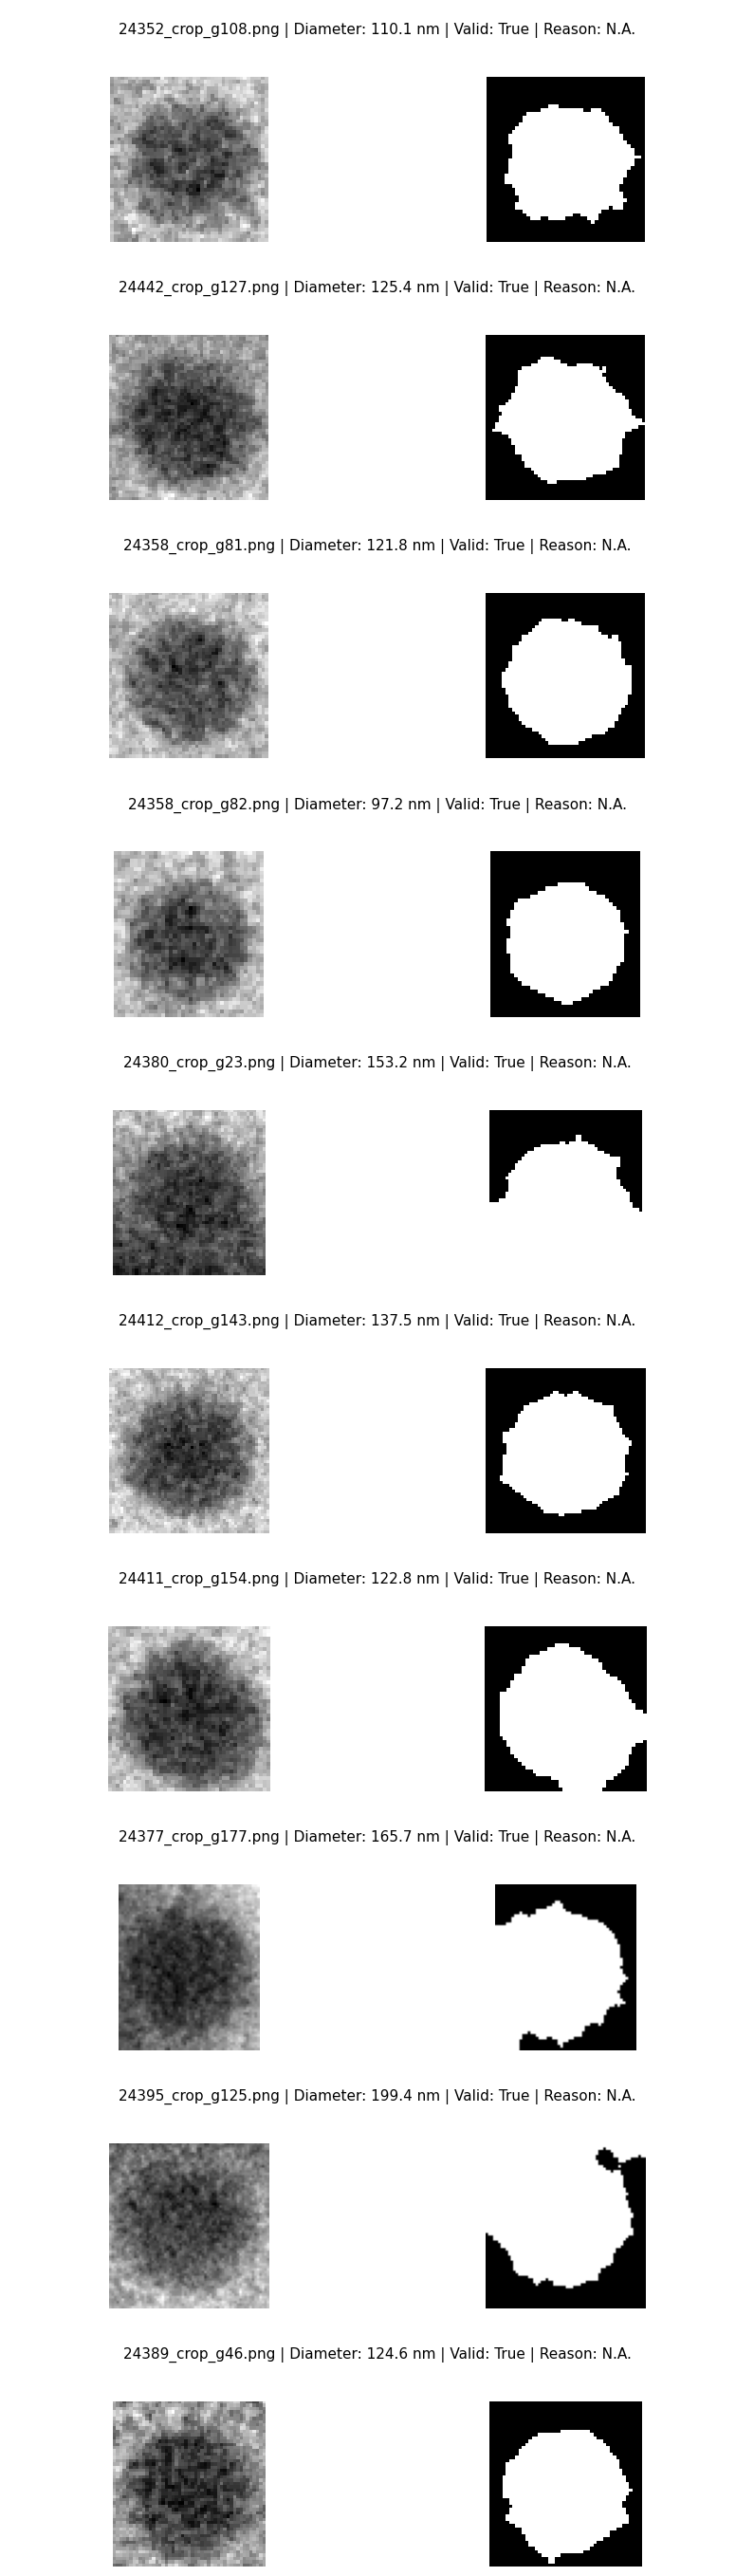

In [75]:
from pathlib import Path
import os
import random

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from PIL import Image
import numpy as np

crop_dir = "/datafiles/crops/2951"

img_paths = [
    p for p in Path(os.getcwd(), crop_dir.lstrip("/")).iterdir()
    if p.is_file() and p.suffix.lower() == ".png"
]

random_imgs = random.sample(img_paths, min(10, len(img_paths)))

pixel_size_nm = 3.22
n = len(random_imgs)

fig = plt.figure(figsize=(10, 3.5 * n))

gs = GridSpec(
    nrows=2 * n,
    ncols=2,
    height_ratios=[0.25, 1] * n,
    hspace=0.25,
    wspace=0.05
)

for row, img_path in enumerate(random_imgs):
    img_arr = np.array(Image.open(img_path))

    result = evaluate_granule(
        img_arr,
        pixel_size_nm=pixel_size_nm,
        diameter_range=(50, 300),
        aspect_ratio_max=1.25
    )

    if result is None:
        img_mask = np.zeros_like(img_arr)
        row_title = f" {img_path.name} | Diameter: N.A. | Valid: False | Reason: No objects found"
    else:
        img_mask, diameter_nm, quality_check, rejection_reason = result

        row_title = (
            f"{img_path.name} | "
            f"Diameter: {diameter_nm:.1f} nm | "
            f"Valid: {quality_check} | "
            f"Reason: {rejection_reason}"
        )

    ax_title = fig.add_subplot(gs[2 * row, :])
    ax_raw = fig.add_subplot(gs[2 * row + 1, 0])
    ax_mask = fig.add_subplot(gs[2 * row + 1, 1])

    ax_title.axis("off")
    ax_title.text(
        0.5,
        0.5,
        row_title,
        ha="center",
        va="center",
        fontsize=11
    )

    ax_raw.imshow(img_arr, cmap="gray")
    ax_raw.axis("off")

    ax_mask.imshow(img_mask, cmap="gray")
    ax_mask.axis("off")

plt.show()